<a href="https://colab.research.google.com/github/bitwise-arnesh/ml-lab-experiments/blob/feature%2Fexperiments-3-4/Experiment-3/Experiment-3-House-Price-Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML Lab Experiment 3

## House Price Prediction using Linear Regression

### Objective

Use Linear and/or Polynomial Regression to train a model on the house training dataset. Clean the dataset, fill missing values, allow for noise, evaluate the model using R-squared (R²), and predict house prices for the given test dataset.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

In [ ]:
# Load the training and testing datasets

train_data = pd.read_csv("house_train - house_train.csv")
test_data = pd.read_csv("house_test - house_test.csv")

print("Training data:")
print(train_data.head())

print("\nTesting data:")
print(test_data.head())

Training data:
   ID  Location Paint_Color  Lot_Width  Lot_Depth  Year_Sold  Year_Built  \
0   1    Suburb       Green        134        NaN       2020        1990   
1   2  Downtown       Green         76       93.0       2025        2019   
2   3    Suburb      Yellow         91       83.0       2019        2003   
3   4    Suburb       Green         26       21.0       2022        1995   
4   5     Rural         Red        138       85.0       2017        1980   

   Living_Area  Num_Rooms      Price  
0          813          6  1548800.0  
1         3093          6  1974800.0  
2         2845          3  2466950.0  
3         1837          3   968700.0  
4         4928          8  2570700.0  

Testing data:
     ID  Location Paint_Color  Lot_Width  Lot_Depth  Year_Sold  Year_Built  \
0  2001     Rural       Green        106        131       2023        1980   
1  2002     Rural       Green         98         23       2016        1984   
2  2003  Downtown       Green         42     

In [ ]:
# Display the shape of the datasets

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

print("\nTraining data columns:")
print(train_data.columns)

print("\nTesting data columns:")
print(test_data.columns)

Training data shape: (2000, 10)
Testing data shape: (1000, 9)

Training data columns:
Index(['ID', 'Location', 'Paint_Color', 'Lot_Width', 'Lot_Depth', 'Year_Sold',
       'Year_Built', 'Living_Area', 'Num_Rooms', 'Price'],
      dtype='object')

Testing data columns:
Index(['ID', 'Location', 'Paint_Color', 'Lot_Width', 'Lot_Depth', 'Year_Sold',
       'Year_Built', 'Living_Area', 'Num_Rooms'],
      dtype='object')


In [ ]:
# Check missing values in the training dataset

print("Missing values in training data:")
print(train_data.isnull().sum())

print("\nMissing values in testing data:")
print(test_data.isnull().sum())

Missing values in training data:
ID               0
Location         0
Paint_Color      0
Lot_Width        0
Lot_Depth      279
Year_Sold        0
Year_Built       0
Living_Area      0
Num_Rooms        0
Price            0
dtype: int64

Missing values in testing data:
ID             0
Location       0
Paint_Color    0
Lot_Width      0
Lot_Depth      0
Year_Sold      0
Year_Built     0
Living_Area    0
Num_Rooms      0
dtype: int64


In [ ]:
# Fill missing values in Lot_Depth using the median

train_data["Lot_Depth"] = train_data["Lot_Depth"].fillna(
    train_data["Lot_Depth"].median()
)

# Check missing values again

print("Missing values after filling:")
print(train_data.isnull().sum())

Missing values after filling:
ID             0
Location       0
Paint_Color    0
Lot_Width      0
Lot_Depth      0
Year_Sold      0
Year_Built     0
Living_Area    0
Num_Rooms      0
Price          0
dtype: int64


In [ ]:
# Check for duplicate rows

print("Number of duplicate rows:", train_data.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
# Remove ID because it is only an identifier

train_data = train_data.drop(columns=["ID"])
test_data = test_data.drop(columns=["ID"])

# Separate input features and target variable

X = train_data.drop(columns=["Price"])
y = train_data["Price"]

print("Input features:")
print(X.columns)

print("\nTarget variable: Price")

Input features:
Index(['Location', 'Paint_Color', 'Lot_Width', 'Lot_Depth', 'Year_Sold',
       'Year_Built', 'Living_Area', 'Num_Rooms'],
      dtype='object')

Target variable: Price


In [ ]:
# Identify numerical and categorical features

numerical_features = [
    "Lot_Width",
    "Lot_Depth",
    "Year_Sold",
    "Year_Built",
    "Living_Area",
    "Num_Rooms"
]

categorical_features = [
    "Location",
    "Paint_Color"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Lot_Width', 'Lot_Depth', 'Year_Sold', 'Year_Built', 'Living_Area', 'Num_Rooms']

Categorical features:
['Location', 'Paint_Color']


In [ ]:
# Convert categorical variables into numerical form

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

In [ ]:
# Create the Linear Regression model

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

In [ ]:
# Train the Linear Regression model

linear_model.fit(X, y)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
# Predict house prices for the training data

y_pred_train = linear_model.predict(X)

print("Training predictions generated successfully.")

Training predictions generated successfully.


In [ ]:
# Calculate R-squared score

r2 = r2_score(y, y_pred_train)

print("R-squared (R²) Score:", r2)

R-squared (R²) Score: 0.2874975834338235


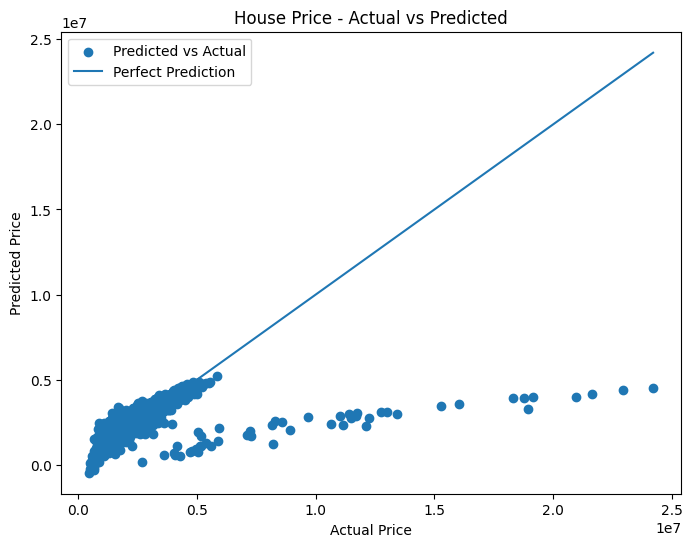

In [ ]:
# Plot actual and predicted house prices

plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred_train, label="Predicted vs Actual")

# Perfect prediction line
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("House Price - Actual vs Predicted")
plt.legend()
plt.show()

In [ ]:
# Prepare the test data

X_test = test_data

# Predict house prices for the test dataset

test_predictions = linear_model.predict(X_test)

print("Predicted house prices for test data:")
print(test_predictions[:10])

Predicted house prices for test data:
[2162807.71278539 2752205.80760501  729418.88732325 2544581.16533794
 2418310.91075031 1265470.67706572 5123006.19519552 2948022.38767048
 1610017.77645411 3754521.23969129]


In [ ]:
# Add predicted prices to the test dataset

test_results = test_data.copy()

test_results["Predicted_Price"] = test_predictions

print(test_results.head(10))

   Location Paint_Color  Lot_Width  Lot_Depth  Year_Sold  Year_Built  \
0     Rural       Green        106        131       2023        1980   
1     Rural       Green         98         23       2016        1984   
2  Downtown       Green         42         45       2020        2014   
3     Rural         Red        100         36       2018        1991   
4     Rural      Yellow         67        111       2021        2021   
5    Suburb       Green        143         50       2020        1982   
6    Suburb       Green        149        126       2024        1991   
7    Suburb       Green        103        130       2023        1985   
8     Rural        Blue         39        120       2023        2005   
9    Suburb       Green         65        131       2024        1994   

   Living_Area  Num_Rooms  Predicted_Price  
0         1076          7     2.162808e+06  
1         4828          2     2.752206e+06  
2         1405          5     7.294189e+05  
3         4853          4  

## Result

The house price dataset was cleaned by identifying and filling missing values. The missing values in the numerical feature `Lot_Depth` were filled using its median value.

The categorical features were converted into numerical form using One-Hot Encoding. A Linear Regression model was trained using the cleaned training dataset.

The model was evaluated using the R-squared (R²) metric. The R² score indicates how well the model explains the variation in house prices.

The trained model was also used to predict house prices for the given test dataset.

## Conclusion

The house price prediction model was successfully developed using Linear Regression. The dataset was cleaned by filling the missing values, and categorical features were encoded before training.

The model was evaluated using the R-squared (R²) criterion. A higher R² value indicates a better fit of the regression model to the data.

The model was able to predict house prices for the provided test dataset while allowing for the natural noise present in the data.